# 1 - Importar bibliotecas para o EDA

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from churn.loader import DataLoader
from scipy import stats

%matplotlib inline

# 2 - Carrega o dataset e printa informações básicas

In [2]:


df = DataLoader(data_path="../data/raw/dataset.csv").load()

print(f"Clientes duplicados (customerID): {df['customerID'].duplicated().sum()}")

df.drop(columns=['customerID'], inplace=True)

print(f"""
Dataset carregado
============================================
Linhas: {df.shape[0]}
Colunas: {df.shape[1]} - {df.columns}
""")
df.head(10)

Clientes duplicados (customerID): 0

Dataset carregado
Linhas: 7043
Colunas: 20 - Index(['gender', 'SeniorCitizen', 'MultipleLines', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')



,gender,SeniorCitizen,MultipleLines,Partner,Dependents,tenure,PhoneService,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,No phone service,Yes,No,1,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,No,34,Yes,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,No,2,Yes,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No phone service,No,No,45,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,No,2,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,Female,0,Yes,No,No,8,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,Male,0,Yes,No,Yes,22,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,Female,0,No phone service,No,No,10,No,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,Female,0,Yes,Yes,No,28,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,Male,0,No,No,Yes,62,Yes,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


# 3 - Prepara a variável alvo e converte TotalCharges para número


In [3]:
df["target"] = df.pop("Churn").map({"Yes": 1, "No": 0})
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# 4 - Informações estatísticas do dataset

In [4]:
print("=== INFORMAÇÕES GERAIS DO DATASET ===\n")
print(df.info())

print("\n=== ESTATÍSTICAS DESCRITIVAS ===\n")
print(df.describe(include="all"))

=== INFORMAÇÕES GERAIS DO DATASET ===

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   MultipleLines     7043 non-null   str    
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod 

# 5 - Validar Missing values

=== ANÁLISE DE MISSING VALUES ===

                    Coluna  Missing_Count  Missing_Percentage
TotalCharges  TotalCharges             11                0.16


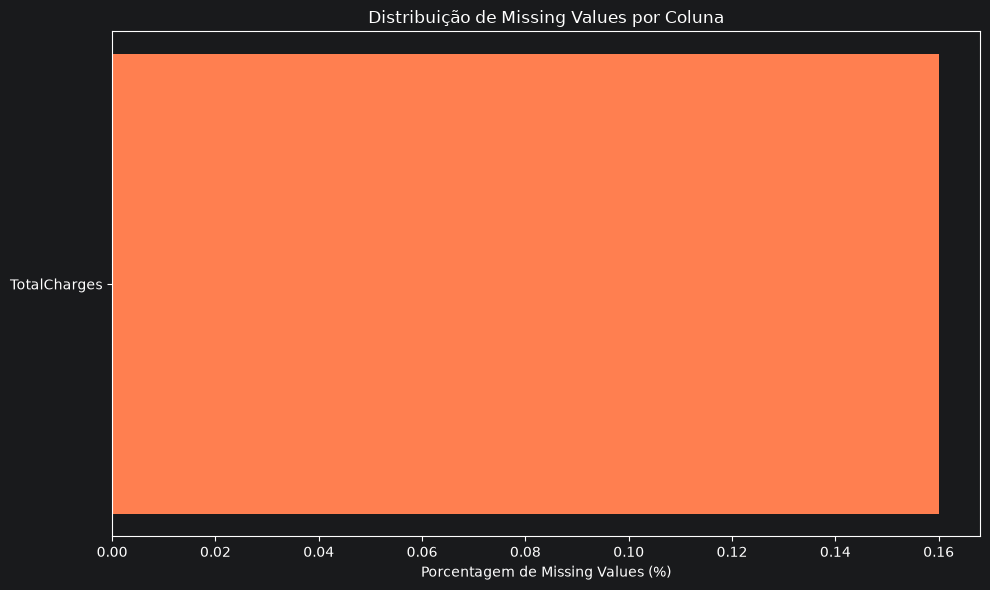

In [5]:
print("=== ANÁLISE DE MISSING VALUES ===\n")
missing_values = pd.DataFrame({
    "Coluna": df.columns,
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})
missing_values = missing_values[missing_values["Missing_Count"] > 0].sort_values(
    by="Missing_Percentage", ascending=False
)

if len(missing_values) > 0:
    print(missing_values)
    plt.figure(figsize=(10, 6))
    plt.barh(missing_values["Coluna"], missing_values["Missing_Percentage"], color="coral")
    plt.xlabel("Porcentagem de Missing Values (%)")
    plt.title("Distribuição de Missing Values por Coluna")
    plt.tight_layout()
    plt.show()
else:
    print("Nenhum missing value detectado!")

In [6]:
df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges", "target"]]

,tenure,MonthlyCharges,TotalCharges,target
488,0,52.55,NaN,0
753,0,20.25,NaN,0
936,0,80.85,NaN,0
1082,0,25.75,NaN,0
1340,0,56.05,NaN,0
3331,0,19.85,NaN,0
3826,0,25.35,NaN,0
4380,0,20.00,NaN,0
5218,0,19.70,NaN,0
6670,0,73.35,NaN,0


# 6 - Verificar distribuição da variável alvo

Distribuição da variável alvo

Contagem:
 target
0    5174
1    1869
Name: count, dtype: int64

Percentual:
 target
0    73.46
1    26.54
Name: proportion, dtype: float64


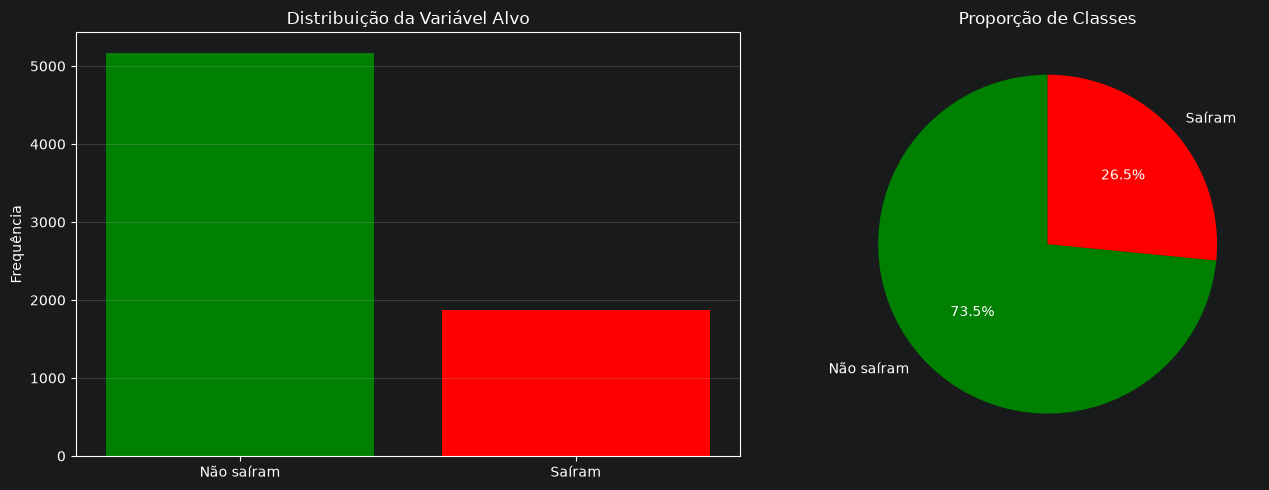


Ratio de balanceamento: 0.36
⚠️ Dataset desbalanceado! Considere usar técnicas como SMOTE ou class_weight.


In [7]:
print("Distribuição da variável alvo")
contagem_alvo = df["target"].value_counts().sort_index()
percentual_alvo = df["target"].value_counts(normalize=True).sort_index() * 100

print("\nContagem:\n", contagem_alvo)
print("\nPercentual:\n", percentual_alvo.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(["Não saíram", "Saíram"], contagem_alvo.values, color=["green", "red"])
axes[0].set_ylabel("Frequência")
axes[0].set_title("Distribuição da Variável Alvo")
axes[0].grid(axis="y", alpha=0.3)

axes[1].pie(contagem_alvo.values, labels=["Não saíram", "Saíram"],
            autopct="%1.1f%%", colors=["green", "red"], startangle=90)
axes[1].set_title("Proporção de Classes")
plt.tight_layout()
plt.show()

ratio = contagem_alvo.min() / contagem_alvo.max()
print(f"\nRatio de balanceamento: {ratio:.2f}")
if ratio < 0.5:
    print("⚠️ Dataset desbalanceado! Considere usar técnicas como SMOTE ou class_weight.")
else:
    print("✓ Dataset razoavelmente balanceado.")

# 7 - Verificar possíveis outliers

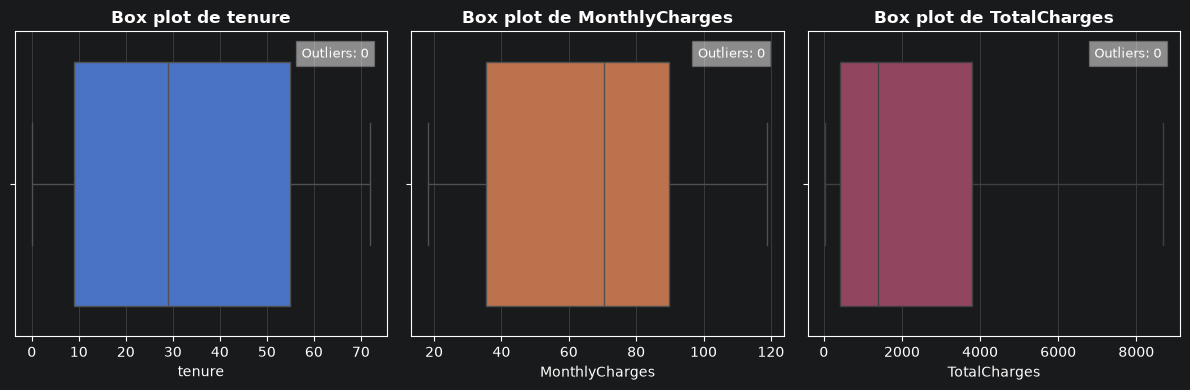

In [8]:
colunas_numericas = df.select_dtypes(include=[np.number]).columns.drop(['target', "SeniorCitizen"])

quantidade_colunas_numericas = len(colunas_numericas)
numero_colunas_plot = 3
numero_linhas_plot = int(np.ceil(quantidade_colunas_numericas / numero_colunas_plot))
figura, axes = plt.subplots(numero_linhas_plot, numero_colunas_plot , figsize=(12, 4 * numero_linhas_plot))
axes = np.atleast_1d(axes).ravel()

for index, coluna in enumerate(colunas_numericas):
    sns.boxplot(x=df[coluna], ax=axes[index], color=sns.color_palette()[index])
    axes[index].set_title(f"Box plot de {coluna}", fontweight='bold')
    axes[index].set_xlabel(coluna)
    axes[index].grid(axis='x', alpha=0.3)

    coluna_zscore = np.abs(stats.zscore(df[coluna], nan_policy='omit'))
    contagem_outlier = (coluna_zscore > 3).sum()
    axes[index].text(0.95, 0.95, f'Outliers: {contagem_outlier}',
                   transform=axes[index].transAxes, fontsize=9,
                   verticalalignment='top', horizontalalignment='right',
                   bbox=dict(facecolor='white', alpha=0.5, edgecolor='gray'))

for ax in axes[quantidade_colunas_numericas:]:
    figura.delaxes(ax)

plt.tight_layout()
plt.show()

# 8 - Variáveis numéricas por classe do alvo

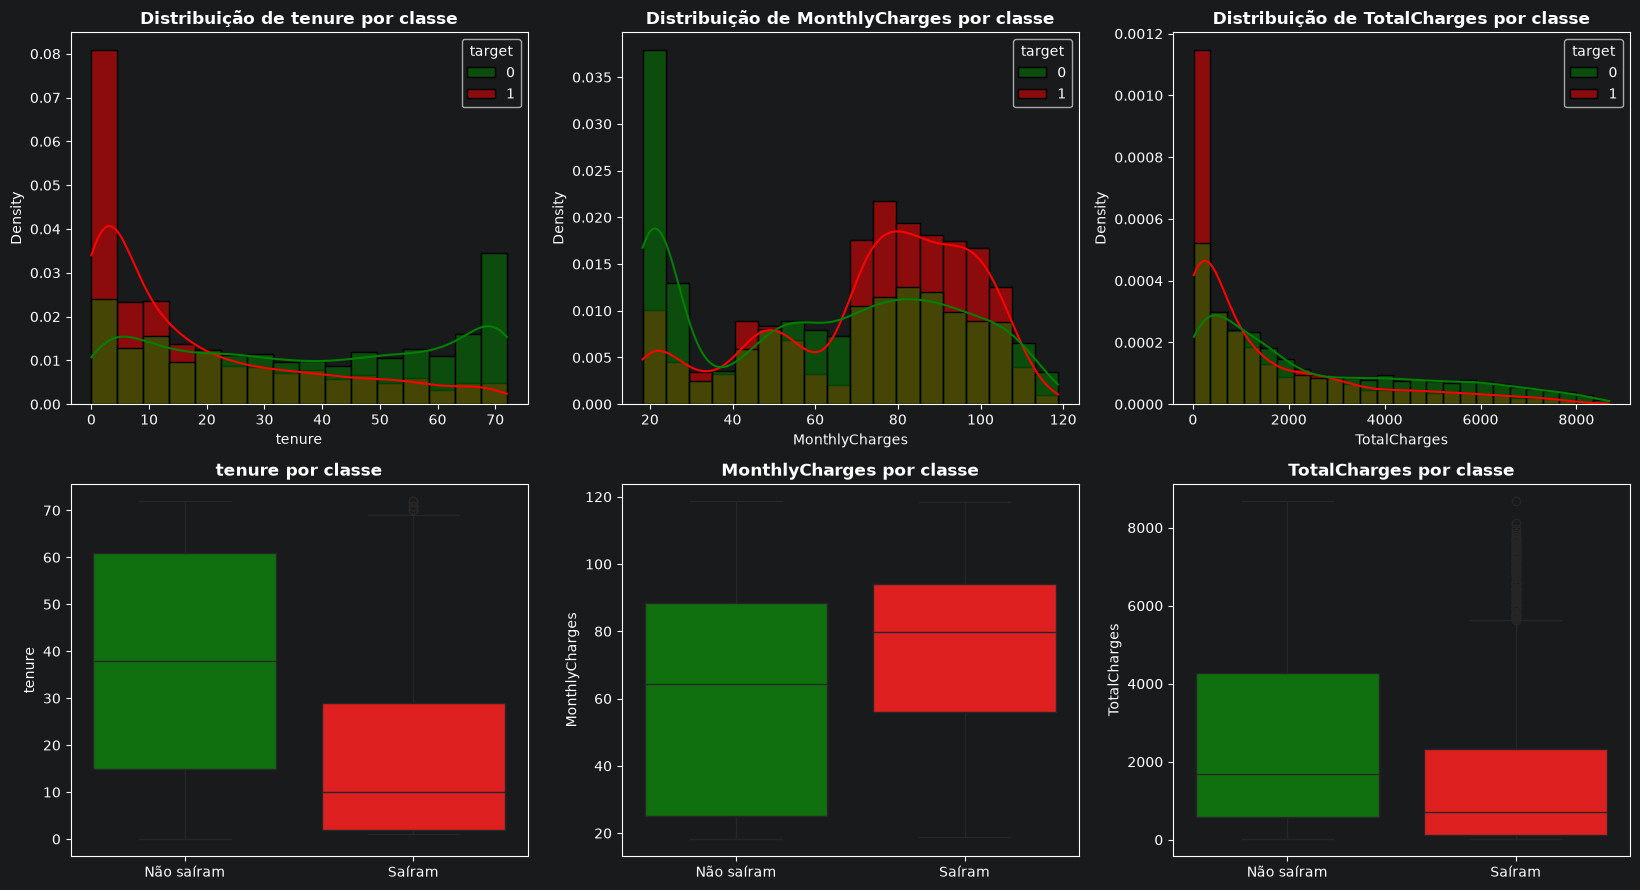

Mediana por classe:
            tenure  MonthlyCharges  TotalCharges
target                                          
Não saíram    38.0          64.425       1683.60
Saíram        10.0          79.650        703.55


In [9]:
n = len(colunas_numericas)
fig, axes = plt.subplots(2, n, figsize=(5.5 * n, 9), squeeze=False)

for index, coluna in enumerate(colunas_numericas):
    sns.histplot(data=df, x=coluna, hue="target", stat="density", common_norm=False,
                 kde=True, ax=axes[0, index], palette=["green", "red"])
    axes[0, index].set_title(f"Distribuição de {coluna} por classe", fontweight="bold")

    sns.boxplot(data=df, x="target", y=coluna, hue="target", legend=False,
            ax=axes[1, index], palette=["green", "red"])
    axes[1, index].set_xticks([0, 1], ["Não saíram", "Saíram"])
    axes[1, index].set_xlabel("")
    axes[1, index].set_title(f"{coluna} por classe", fontweight="bold")

plt.tight_layout()
plt.show()

print("Mediana por classe:")
print(df.groupby("target")[list(colunas_numericas)].median().rename(index={0: "Não saíram", 1: "Saíram"}))

# 9 - Correlação entre TotalCharges, tenure e MonthlyCharges

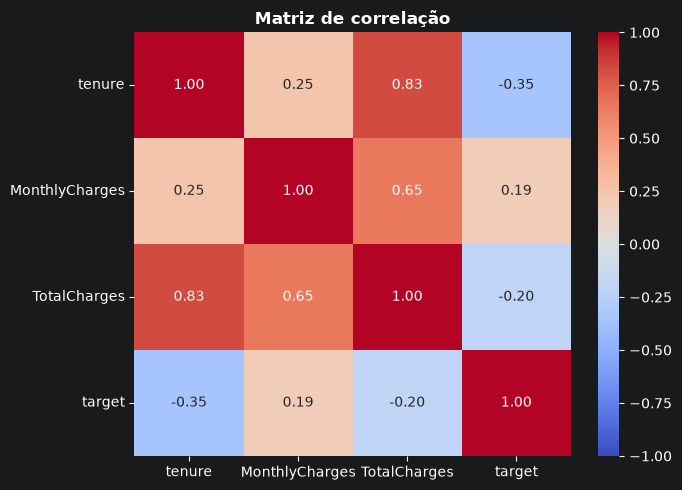

Correlação entre TotalCharges e tenure × MonthlyCharges: 1.000


In [10]:
correlacao = df[["tenure", "MonthlyCharges", "TotalCharges", "target"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlação", fontweight="bold")
plt.tight_layout()
plt.show()

estimado = df["tenure"] * df["MonthlyCharges"]
print(f"Correlação entre TotalCharges e tenure × MonthlyCharges: {df['TotalCharges'].corr(estimado):.3f}")

# 10 - Taxa de churn por variável categórica

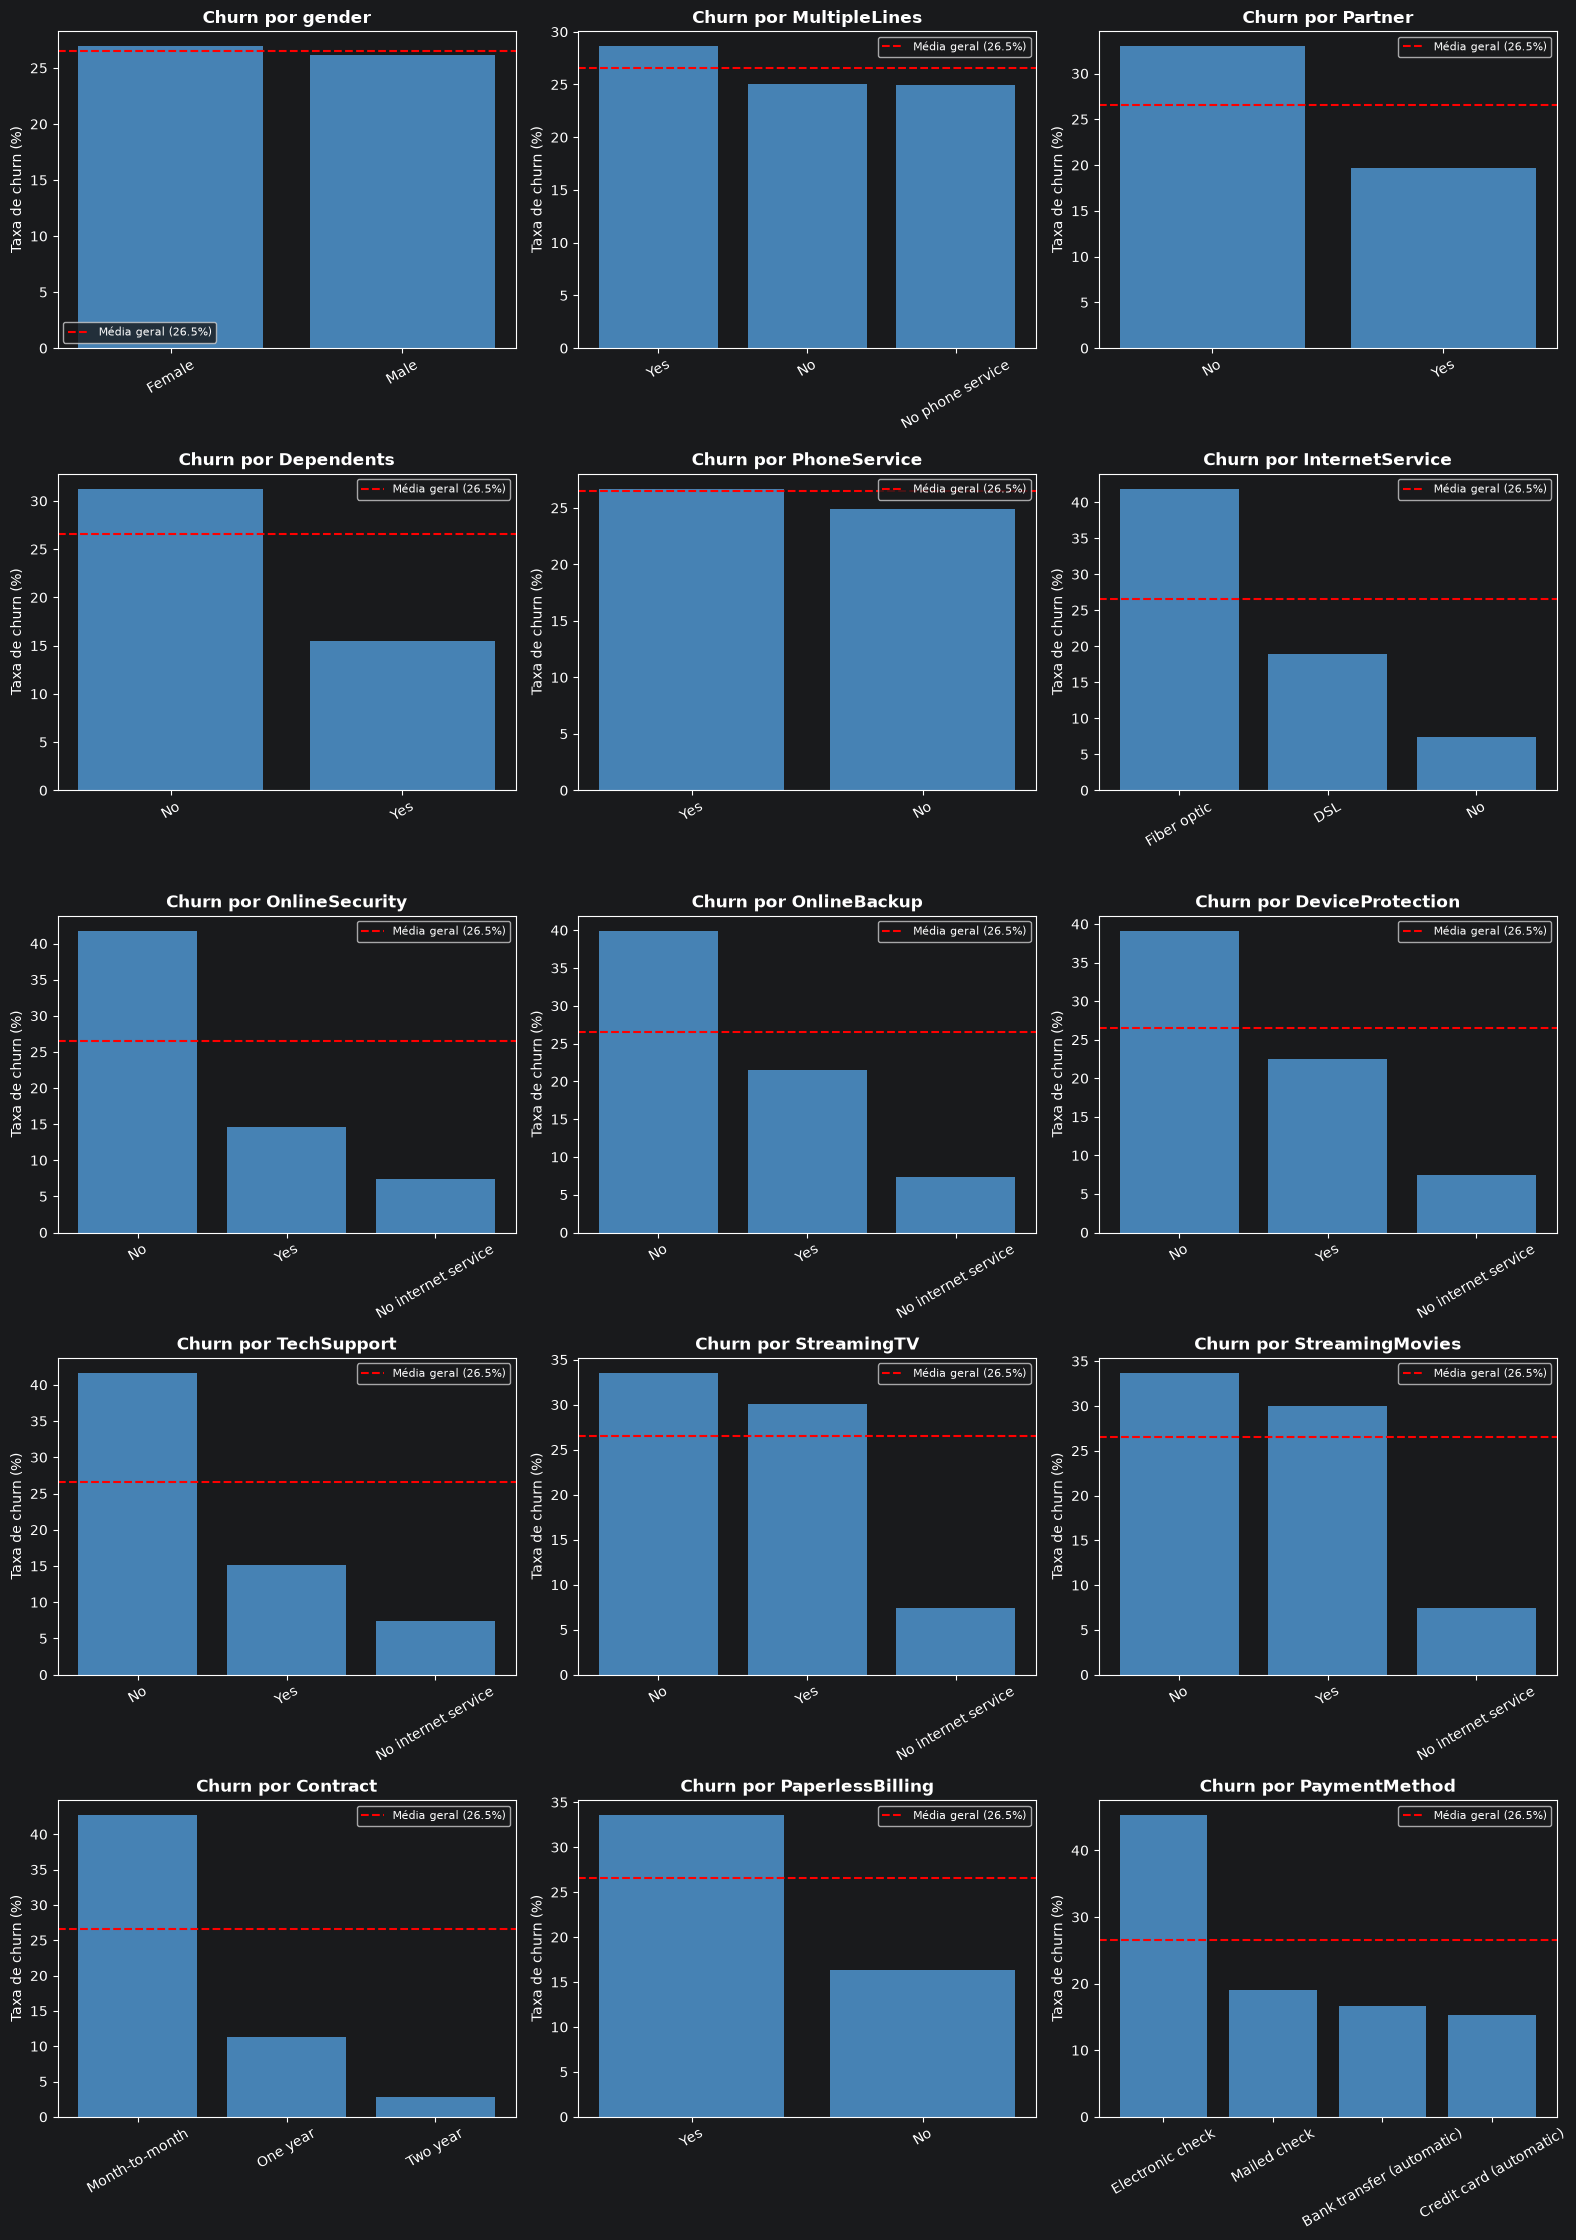

In [11]:
colunas_categoricas = df.select_dtypes(include=["object", "str"]).columns
taxa_geral = df["target"].mean() * 100

numero_linhas_plot = int(np.ceil(len(colunas_categoricas) / 3))
figura, axes = plt.subplots(numero_linhas_plot, 3, figsize=(16, 4.5 * numero_linhas_plot))
axes = np.atleast_1d(axes).ravel()

for index, coluna in enumerate(colunas_categoricas):
    taxa = (df.groupby(coluna)["target"].mean() * 100).sort_values(ascending=False)
    axes[index].bar(taxa.index.astype(str), taxa.values, color="steelblue")
    axes[index].axhline(taxa_geral, color="red", linestyle="--", label=f"Média geral ({taxa_geral:.1f}%)")
    axes[index].set_title(f"Churn por {coluna}", fontweight="bold")
    axes[index].set_ylabel("Taxa de churn (%)")
    axes[index].tick_params(axis="x", rotation=30)
    axes[index].legend(fontsize=8)

for ax in axes[len(colunas_categoricas):]:
    figura.delaxes(ax)

plt.tight_layout()
plt.show()

# Considerações Finais

O dataset **possui** colunas com os valores "Yes", "No", "No internet service" e "No phone service". Como "No internet service" e "No phone service" indicam que o cliente não utilizava o respectivo serviço, eles **serão mapeados** para "No", padronizando os dados entre "Yes" e "No" para a futura transformação em 1 e 0 durante a limpeza. Essa informação não se perde, pois já está representada nas colunas `InternetService` e `PhoneService`.

A coluna `TotalCharges` foi carregada como texto porque alguns registros contêm espaços em branco. Após a conversão para número, esses registros aparecem como valores ausentes e correspondem a clientes com `tenure` igual a 0, ou seja, que ainda não foram cobrados; por isso **serão preenchidos** com 0 na limpeza. A coluna é fortemente correlacionada com `tenure` e com o produto `tenure × MonthlyCharges`, o que indica redundância; na modelagem, **será testado** o desempenho com e sem ela.

Não há clientes duplicados (`customerID` único). Linhas com características idênticas após a remoção do ID representam clientes distintos e **não serão removidas**.

Clientes que cancelaram tendem a ter `tenure` menor e `MonthlyCharges` maior. Entre as variáveis categóricas, as maiores taxas de churn aparecem em contratos mensais, pagamento por cheque eletrônico e internet por fibra óptica.

Por fim, o dataset está desbalanceado em relação à classe de *churn*, portanto **serão avaliadas** técnicas de balanceamento (como `class_weight` ou SMOTE) na etapa de modelagem, aplicadas apenas aos dados de treino.